# Agentic Research Assistant — LangGraph Demo

This notebook demonstrates a multi-tool scientific research assistant built using LangChain and LangGraph.

**Capabilities:**
- PubMed literature search
- Tavily web search
- Wikipedia background research
- Mathematical calculations
- Dynamic tool selection
- Conversation memory
- Node-level execution streaming

The agent implementation is maintained in `src/agent.py`, keeping this notebook focused on demonstrations and results.

In [1]:
# Import the compiled LangGraph agent from the project
import sys
from pathlib import Path

# Locate the project root
project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Allow imports from src/
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.agent import graph, tools

# Verify successful initialisation
print("Research assistant initialised successfully.")
print("\nAvailable tools:")

for tool in tools:
    print(f"- {tool.name}")

Research assistant initialised successfully.

Available tools:
- pubmed_search
- web_search
- wikipedia_search
- calculator


## 1. PubMed Literature Search

This experiment demonstrates how the LangGraph agent selects the
PubMed tool to retrieve biomedical research publications.

The agent should return relevant papers with titles, publication
details and PubMed references.

In [2]:
# Experiment 1 — Scientific literature retrieval

# Use a unique conversation thread
config = {
    "configurable": {
        "thread_id": "demo_pubmed_1"
    }
}

# Define the research question
query = (
    "Search PubMed for deep learning applications in "
    "prostate cancer MRI. Identify two relevant publications "
    "and provide their titles, publication years and PubMed URLs."
)

# Invoke the LangGraph agent
response = graph.invoke(
    {"messages": [("user", query)]},
    config=config
)

# Display the final research response
print(response["messages"][-1].content)

# Display which tools the agent selected
tools_used = [
    call["name"]
    for msg in response["messages"]
    for call in getattr(msg, "tool_calls", [])
]

print("\nTools used:", tools_used)

Here are two relevant publications on deep learning applications in prostate cancer MRI:

1. **Title:** Machine learning applications in prostate cancer magnetic resonance imaging  
   **Authors:** Cuocolo R, Cipullo MB, Stanzione A  
   **Publication Year:** 2019  
   **PubMed URL:** [https://pubmed.ncbi.nlm.nih.gov/31392526/](https://pubmed.ncbi.nlm.nih.gov/31392526/)

2. **Title:** Advancing Prostate Cancer Diagnosis: A Deep Learning Approach for Enhanced Detection in MRI Images  
   **Authors:** Horasan A, Gunes A  
   **Publication Year:** 2024  
   **PubMed URL:** [https://pubmed.ncbi.nlm.nih.gov/39272656/](https://pubmed.ncbi.nlm.nih.gov/39272656/) 

These publications discuss the integration of machine learning and deep learning techniques in the context of prostate cancer MRI, highlighting their potential applications and advancements in diagnostic accuracy.

Tools used: ['pubmed_search']


## 2. Dynamic Tool Selection — Web Search and Wikipedia

This experiment demonstrates how the agent chooses between:

- **Tavily:** Current research developments and web information.
- **Wikipedia:** General knowledge and established scientific concepts.

The tool is selected dynamically by the LLM.

In [3]:
# Experiment 2 — Dynamic tool selection

queries = [
    "Search the web for recent developments in AI for medical imaging.",
    "Use Wikipedia to explain what a convolutional neural network is."
]

for i, query in enumerate(queries, start=1):

    # Separate conversation threads to avoid context interference
    config = {
        "configurable": {
            "thread_id": f"demo_tool_selection_{i}"
        }
    }

    # Invoke the research agent
    response = graph.invoke(
        {"messages": [("user", query)]},
        config=config
    )

    # Extract the tools selected by the agent
    tools_used = [
        call["name"]
        for msg in response["messages"]
        for call in getattr(msg, "tool_calls", [])
    ]

    print(f"\n{'=' * 60}")
    print(f"QUESTION {i}: {query}")
    print(f"\nTOOLS USED: {tools_used}")
    print(f"\nRESPONSE:\n{response['messages'][-1].content}")


QUESTION 1: Search the web for recent developments in AI for medical imaging.

TOOLS USED: ['web_search']

RESPONSE:
Here are some recent developments in AI for medical imaging as of 2023:

1. **Pillar AI Model**: Researchers from UC Berkeley and UCSF developed a vision language model named Pillar, which analyzes CT and MRI images. It achieved an average AUC of 0.87 across over 350 findings, outperforming existing models like Google's MedGemma and Microsoft's MI2. This model can be fine-tuned for specific clinical challenges, showing improved performance in lung cancer prediction and brain hemorrhage detection. [Read more here](https://www.itnonline.com/content/researchers-release-new-ai-model-medical-imaging).

2. **AI in Radiology**: A critical review highlighted that 213 out of 222 registered AI medical devices are now certified, indicating a significant shift towards acceptance in medical institutions. The review also discussed the adoption of over 500 FDA-approved AI devices in t

## 3. Multi-Tool Reasoning — PubMed and Calculator

This experiment demonstrates how the agent combines:
- **PubMed Search:** Retrieve reported scientific findings.
- **Calculator:** Perform numerical calculations using retrieved values.

The objective is to compare the external-test AUC values of a deep learning model and radiologists, using evidence from a published study.

In [4]:
# Experiment 3 — Multi-tool research and calculation

config = {
    "configurable": {
        "thread_id": "demo_multi_tool_1"
    }
}

# Define a question requiring two tools
query = (
    "Search PubMed for the study titled 'Fully Automated Deep Learning "
    "Model to Detect Clinically Significant Prostate Cancer at MRI'. "
    "Find the external-test AUC values for the deep learning model "
    "and radiologists. Use the calculator to compute the difference "
    "in percentage points. Cite the publication."
)

# Invoke the agent
response = graph.invoke(
    {"messages": [("user", query)]},
    config=config
)

# Display the final response
print("RESEARCH RESPONSE:\n")
print(response["messages"][-1].content)

# Show the tools requested by the agent
print("\nTOOLS USED:")
for msg in response["messages"]:
    for call in getattr(msg, "tool_calls", []):
        print(f"- {call['name']}: {call['args']}")

RESEARCH RESPONSE:

The study titled **"Fully Automated Deep Learning Model to Detect Clinically Significant Prostate Cancer at MRI"** reports the following external-test AUC values:

- Deep Learning (DL) model: **0.86**
- Radiologists: **0.84**

The difference in AUC values is approximately **2 percentage points**.

You can access the publication [here](https://pubmed.ncbi.nlm.nih.gov/39105640/).

TOOLS USED:
- pubmed_search: {'query': 'Fully Automated Deep Learning Model to Detect Clinically Significant Prostate Cancer at MRI'}
- calculator: {'expression': '(0.86 - 0.84) * 100'}


## 4. Conversation Memory

This experiment demonstrates LangGraph's `MemorySaver` checkpointing.

The agent uses the same `thread_id` to remember a previous research question and answer a follow-up without manually passing conversation history.

In [5]:
# Experiment 4 — Conversation memory

# Reuse the same thread from Experiment 3
config = {
    "configurable": {
        "thread_id": "demo_multi_tool_1"
    }
}

# Ask a follow-up without repeating the paper's title
query = "What was the title and publication year of that study?"

response = graph.invoke(
    {"messages": [("user", query)]},
    config=config
)

# Display the response
print("FOLLOW-UP RESPONSE:\n")
print(response["messages"][-1].content)

# Check stored conversation history
print("\nMessages in memory:", len(response["messages"]))

FOLLOW-UP RESPONSE:

The title of the study is **"Fully Automated Deep Learning Model to Detect Clinically Significant Prostate Cancer at MRI,"** and it was published in the year **2024**.

Messages in memory: 8


## 5. Node-Level Streaming

This experiment uses LangGraph's `stream()` method to display execution updates as each node completes.

It demonstrates the sequence of tool selection, tool execution and final response generation.

In [6]:
# Experiment 5 — Stream LangGraph execution updates

config = {
    "configurable": {
        "thread_id": "demo_streaming_1"
    }
}

query = (
    "Use Wikipedia to find information about Alan Turing "
    "and briefly explain his contributions to computing."
)

# Stream updates as each graph node completes
for event in graph.stream(
    {"messages": [("user", query)]},
    config=config,
    stream_mode="updates"
):
    for node_name, node_output in event.items():
        print(f"\n--- Node: {node_name} ---")

        for message in node_output.get("messages", []):

            # Display requested tool calls
            if getattr(message, "tool_calls", None):
                for call in message.tool_calls:
                    print(f"Tool requested: {call['name']}")
                    print(f"Arguments: {call['args']}")

            # Display tool results (truncated)
            elif message.type == "tool":
                print(f"Tool result: {str(message.content)[:250]}...")

            # Display final AI responses
            elif message.type == "ai" and message.content:
                print(f"Agent response: {message.content}")


--- Node: research_agent ---
Tool requested: wikipedia_search
Arguments: {'query': 'Alan Turing'}

--- Node: tools ---
Tool result: Page: Alan Turing
Summary: Alan Mathison Turing (; 23 June 1912 – 7 June 1954) was an English mathematician and logician widely regarded as the father of theoretical computer science. He formalised the concepts of algorithm and computation with the T...

--- Node: research_agent ---
Agent response: Alan Turing (1912–1954) was an English mathematician and logician, often regarded as the father of theoretical computer science. His key contributions include:

1. **Turing Machine**: He formalized the concepts of algorithm and computation through the Turing machine, a theoretical model that serves as a foundation for modern computing.

2. **Cryptanalysis**: During World War II, Turing played a crucial role in breaking the German Enigma code at Bletchley Park, significantly aiding the Allies' war efforts. His work on cryptanalysis led to the development of tech

## 6. LangGraph Architecture

The research assistant uses a cyclic LangGraph workflow.

The LLM dynamically selects from four tools: PubMed, Tavily, Wikipedia and Calculator. Tool results return to the research agent, which can request further tools or generate a final answer.

Conversation history is managed through LangGraph's `MemorySaver` checkpointer.

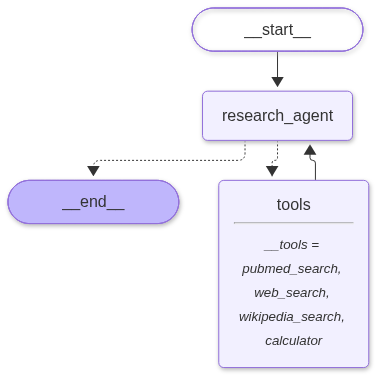

Architecture diagram saved to: C:\Users\sy_be\Projects\Agentic-Research-Assistant-LangGraph\results\langgraph_architecture.png


In [7]:
# Experiment 6 — Visualise and save the LangGraph architecture

from IPython.display import Image, display
from pathlib import Path

# Directory for saved project figures
results_dir = project_root / "results"
results_dir.mkdir(exist_ok=True)

# Generate the architecture diagram
graph_image = graph.get_graph().draw_mermaid_png()

# Display it in the notebook
display(Image(graph_image))

# Save the diagram for the GitHub README
output_path = results_dir / "langgraph_architecture.png"
output_path.write_bytes(graph_image)

print(f"Architecture diagram saved to: {output_path}")

## 7. Conclusion

This notebook demonstrates a multi-tool scientific research assistant built with LangGraph.

### Implemented capabilities

- **Dynamic tool selection:** The LLM selects appropriate research tools.
- **Scientific retrieval:** PubMed provides biomedical publications and abstracts.
- **Web research:** Tavily retrieves broader web information.
- **Background knowledge:** Wikipedia provides general explanations.
- **Numerical reasoning:** A calculator performs mathematical operations.
- **Multi-tool workflows:** The agent combines retrieval and calculation.
- **Conversation memory:** MemorySaver maintains state across interactions.
- **Execution streaming:** LangGraph exposes node-level execution updates.

### Future improvements

- Document-based Retrieval-Augmented Generation (RAG).
- Persistent conversation storage.
- More comprehensive automated testing and evaluation.
- Improved citation validation and error handling.

**Architecture:** The LangGraph workflow is visualised above and saved in `results/langgraph_architecture.png`.